# UPI Transaction Fraud detection Using Machine Learning
## A Classification-Based Approach for Imbalanced Data

### 1. Project Overview
This project focuses on identifying potentially fraudulent UPI tranacations uisng machine learning classification techniques. The goal is to built and evalute a model that can distinguish fraudulent tranactions from genuine ones.

### 2. Project Objectives
Analyze tranaction data to identify patterns associated with fraud.
Prepare the dataset fro machine learning.
Train and evaluate classification models on imbalanced transaction data.
compare model performance and select an appropriate fraud-detection threshold.

## 1. Load the Dataset

**Objective:** Load the selected UPI transaction dataset into a Pandas DataFrame. Display the first five records to understand the structure and format of the transaction data.

In [1]:

import pandas as pd
from pathlib import Path

# Define the path to our selected enhanced dataset
DATA_PATH = Path(
    r"E:\UPI_Fraud_Detection\data\upi_transactions_synthetic_enhanced_final.csv"
)

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(DATA_PATH)

# Display the first five transactions
display(df.head())


,transaction_id,timestamp,user_id,device_id,payee_id,payee_type,merchant_category,transaction_type,amount_inr,transaction_latitude,...,is_offer_exposed,offer_type,is_power_outage,is_network_disruption,disruption_type,retry_count,payment_attempt_count,is_payment_retry,is_traveling,location_context
0,TX0085271,2025-04-01 00:07:48,U02348,DEV_U02348_PRIMARY,P00939,Individual,Personal,Pay,1425.37,17.524998,...,0,No offer,0,0,No disruption,0,1,0,0,Local/regular area
1,TX0033796,2025-04-01 00:09:24,U02134,DEV_U02134_PRIMARY,P00450,Individual,Personal,Pay,1198.75,11.751157,...,0,No offer,0,0,No disruption,0,1,0,1,Travel/away from home
2,TX0027901,2025-04-01 00:12:24,U02155,DEV_U02155_PRIMARY,P00993,Merchant,Other,Pay,519.50,18.021511,...,0,No offer,0,0,No disruption,0,1,0,0,Local/regular area
3,TX0017961,2025-04-01 00:15:15,U00025,DEV_U00025_PRIMARY,P01618,Individual,Personal,Pay,228.76,18.350037,...,0,No offer,0,0,No disruption,0,1,0,0,Local/regular area
4,TX0003069,2025-04-01 00:21:26,U02065,DEV_U02065_PRIMARY,P02740,Individual,Personal,Pay,175.60,26.848627,...,0,No offer,0,0,No disruption,0,1,0,0,Local/regular area


## 2. Inspect Dataset Structure and Fraud Distribution

**Objective:** Examine the dataset's dimensions, column names, data types, and non-null counts. Analyze the distribution of genuine and fraudulent transactions to understand the class imbalance in the dataset.

In [2]:

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nFraud label distribution:")
print(df["is_fraud"].value_counts())

print("\nFraud percentages:")
print((df["is_fraud"].value_counts(normalize=True) * 100).round(2))


Dataset shape: (100000, 43)

Column names:
['transaction_id', 'timestamp', 'user_id', 'device_id', 'payee_id', 'payee_type', 'merchant_category', 'transaction_type', 'amount_inr', 'transaction_latitude', 'transaction_longitude', 'distance_from_home_km', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_night', 'is_new_device', 'is_new_payee', 'payee_account_age_days', 'txns_last_1h', 'txns_last_24h', 'distinct_payees_last_24h', 'minutes_since_last_txn', 'historical_avg_amount', 'amount_to_avg_ratio', 'balance_before_inr', 'balance_drain_ratio', 'is_fraud', 'is_festival_period', 'festival_name', 'is_sale_day', 'sale_campaign', 'is_payday_period', 'is_offer_exposed', 'offer_type', 'is_power_outage', 'is_network_disruption', 'disruption_type', 'retry_count', 'payment_attempt_count', 'is_payment_retry', 'is_traveling', 'location_context']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 43 columns):
 #   Column 

## 3. Analyze Class Distribution

**Objective:** Calculate the number and percentage of genuine and fraudulent transactions. Visualize the class distribution to understand the imbalance between the two transaction classes.

Transaction counts:
is_fraud
Genuine    99000
Fraud       1000
Name: count, dtype: int64

Transaction percentages:
is_fraud
Genuine    99.0
Fraud       1.0
Name: proportion, dtype: float64


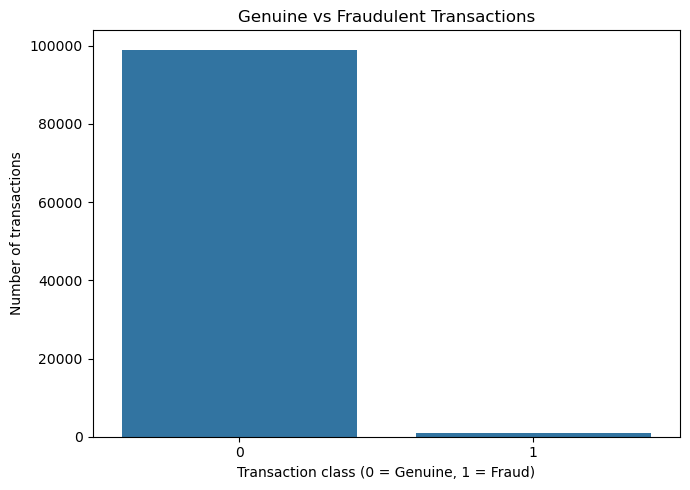

In [3]:

import matplotlib.pyplot as plt
import seaborn as sns

# Calculate transaction counts
fraud_counts = df["is_fraud"].value_counts().sort_index()

# Display counts and percentages
print("Transaction counts:")
print(fraud_counts.rename(index={0: "Genuine", 1: "Fraud"}))

print("\nTransaction percentages:")
print(
    (df["is_fraud"].value_counts(normalize=True).sort_index() * 100)
    .rename(index={0: "Genuine", 1: "Fraud"})
    .round(2)
)

# Plot the class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="is_fraud")
plt.title("Genuine vs Fraudulent Transactions")
plt.xlabel("Transaction class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Number of transactions")
plt.tight_layout()
plt.show()


## 4. Analyze Transaction Amounts by Fraud Class

**Objective:** Compare transaction amount statistics for genuine and fraudulent transactions. Use a box plot to visualize differences in transaction amounts between the two classes.

Transaction amount summary (INR):
           count     mean      std    min     25%      50%      75%       max
Genuine  99000.0   696.35   977.24   9.05  204.24   408.74   817.76  37399.64
Fraud     1000.0  1603.35  1656.68  59.48  609.93  1103.32  2000.57  16346.95


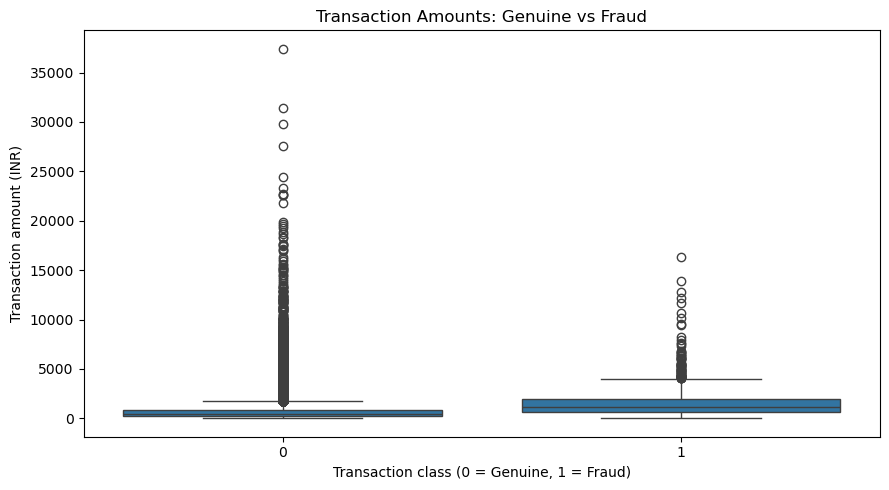

In [4]:

# Compare transaction amount statistics by fraud label
amount_summary = df.groupby("is_fraud")["amount_inr"].describe()

amount_summary.index = ["Genuine", "Fraud"]

print("Transaction amount summary (INR):")
print(amount_summary.round(2))

# Visualize transaction amounts by class
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="is_fraud",
    y="amount_inr"
)

plt.title("Transaction Amounts: Genuine vs Fraud")
plt.xlabel("Transaction class (0 = Genuine, 1 = Fraud)")
plt.ylabel("Transaction amount (INR)")
plt.tight_layout()
plt.show()


## 5. Analyze Fraud Rates by Transaction Type

**Objective:** Compare genuine and fraudulent transaction counts across different transaction types. Calculate the fraud rate for each type and visualize the results to identify transaction categories with higher fraud rates.

Transaction counts by type:
is_fraud          Genuine  Fraud
transaction_type                
Collect_Request      4810    345
Pay                 94190    655

Fraud rate by transaction type:
                  Total_transactions  Fraud_transactions  Fraud_rate_pct
transaction_type                                                        
Collect_Request                 5155                 345            6.69
Pay                            94845                 655            0.69


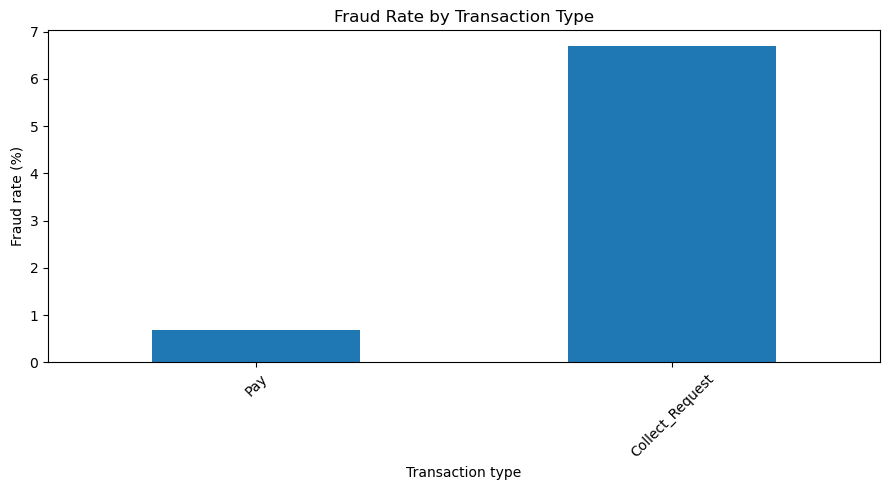

In [5]:

# Count transactions by type and fraud label
type_counts = pd.crosstab(
    df["transaction_type"],
    df["is_fraud"],
    margins=False
)

type_counts = type_counts.rename(columns={
    0: "Genuine",
    1: "Fraud"
})

# Calculate fraud rate within each transaction type
fraud_rate_by_type = (
    df.groupby("transaction_type")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total_transactions",
        "sum": "Fraud_transactions",
        "mean": "Fraud_rate"
    })
)

fraud_rate_by_type["Fraud_rate_pct"] = (
    fraud_rate_by_type["Fraud_rate"] * 100
)

print("Transaction counts by type:")
print(type_counts)

print("\nFraud rate by transaction type:")
print(
    fraud_rate_by_type[
        ["Total_transactions", "Fraud_transactions", "Fraud_rate_pct"]
    ].round(2)
)

# Visualize fraud rates by type
fraud_rate_by_type["Fraud_rate_pct"].sort_values().plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Fraud Rate by Transaction Type")
plt.xlabel("Transaction type")
plt.ylabel("Fraud rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 6. Analyze Fraud Rates by Hour of Day

**Objective:** Calculate the number of transactions and fraud rate for each hour of the day. Visualize hourly fraud patterns to identify times when fraudulent transactions occur more frequently.

Fraud rate by hour:
             Total_transactions  Fraud_transactions  Fraud_rate_pct
hour_of_day                                                        
0                          3708                 111            2.99
1                          3740                 117            3.13
2                          3779                 117            3.10
3                          3741                 106            2.83
4                          3746                 104            2.78
5                          3668                 106            2.89
6                          3687                  11            0.30
7                          3634                  14            0.39
8                          4504                  21            0.47
9                          4532                  12            0.26
10                         4454                  21            0.47
11                         4601                  21            0.46
12                         4

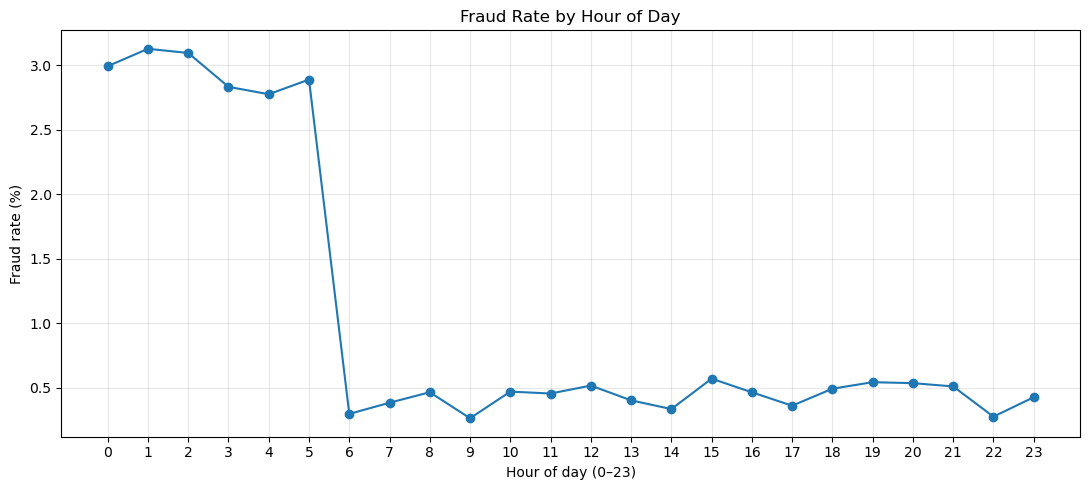

In [6]:

# Calculate transaction counts and fraud rates by hour
fraud_by_hour = (
    df.groupby("hour_of_day")["is_fraud"]
    .agg(["count", "sum", "mean"])
    .rename(columns={
        "count": "Total_transactions",
        "sum": "Fraud_transactions",
        "mean": "Fraud_rate"
    })
)

fraud_by_hour["Fraud_rate_pct"] = fraud_by_hour["Fraud_rate"] * 100

print("Fraud rate by hour:")
print(
    fraud_by_hour[
        ["Total_transactions", "Fraud_transactions", "Fraud_rate_pct"]
    ].round(2)
)

# Plot fraud rate throughout the day
plt.figure(figsize=(11, 5))
plt.plot(
    fraud_by_hour.index,
    fraud_by_hour["Fraud_rate_pct"],
    marker="o"
)

plt.title("Fraud Rate by Hour of Day")
plt.xlabel("Hour of day (0–23)")
plt.ylabel("Fraud rate (%)")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Analyze Fraud Rates by Device and Payee

**Objective:** Compare fraud rates for transactions involving new devices and new payees against those that do not. Visualize the results to identify potential patterns associated with fraudulent transactions.


Fraud analysis for is_new_device:
               Total_transactions  Fraud_transactions  Fraud_rate_pct
is_new_device                                                        
No                          96835                 639            0.66
Yes                          3165                 361           11.41

Fraud analysis for is_new_payee:
              Total_transactions  Fraud_transactions  Fraud_rate_pct
is_new_payee                                                        
No                         40659                 109            0.27
Yes                        59341                 891            1.50


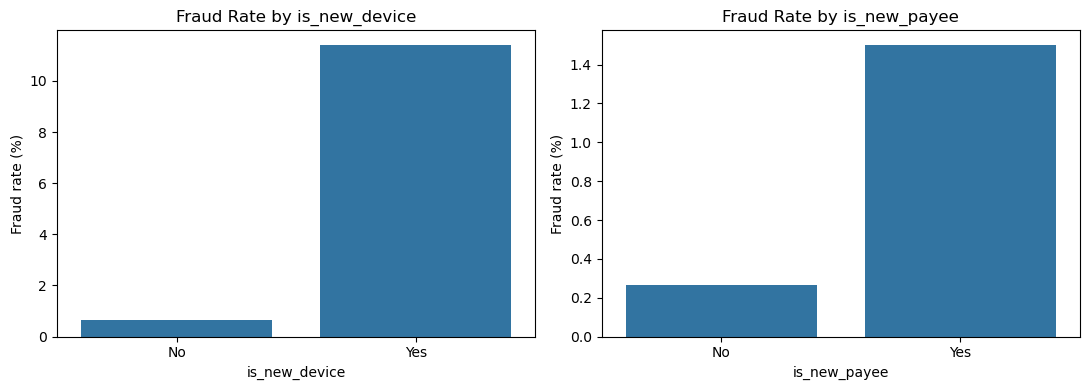

In [7]:

# Calculate fraud counts and rates for new-device and new-payee indicators
for feature in ["is_new_device", "is_new_payee"]:
    summary = (
        df.groupby(feature)["is_fraud"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "Total_transactions",
            "sum": "Fraud_transactions",
            "mean": "Fraud_rate"
        })
    )

    summary["Fraud_rate_pct"] = summary["Fraud_rate"] * 100
    summary.index = summary.index.map({
        0: "No",
        1: "Yes"
    })

    print(f"\nFraud analysis for {feature}:")
    print(
        summary[
            ["Total_transactions", "Fraud_transactions", "Fraud_rate_pct"]
        ].round(2)
    )

# Visualize fraud rates for both features
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, feature in zip(
    axes,
    ["is_new_device", "is_new_payee"]
):
    rates = df.groupby(feature)["is_fraud"].mean() * 100

    sns.barplot(
        x=["No", "Yes"],
        y=rates.values,
        ax=ax
    )

    ax.set_title(f"Fraud Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.show()


## 8. Analyze Fraud Rates by Contextual Factors

**Objective:** Compare fraud rates during festival periods, sale days, payday periods, and offer exposure. Visualize the results to identify potential relationships between these contextual factors and fraudulent transactions.


Fraud analysis for is_festival_period:
                    Total_transactions  Fraud_transactions  Fraud_rate_pct
is_festival_period                                                        
No                               90095                 851            0.94
Yes                               9905                 149            1.50

Fraud analysis for is_sale_day:
             Total_transactions  Fraud_transactions  Fraud_rate_pct
is_sale_day                                                        
No                        82108                 772            0.94
Yes                       17892                 228            1.27

Fraud analysis for is_payday_period:
                  Total_transactions  Fraud_transactions  Fraud_rate_pct
is_payday_period                                                        
No                             71818                 690            0.96
Yes                            28182                 310            1.10

Fraud analysis for is_of

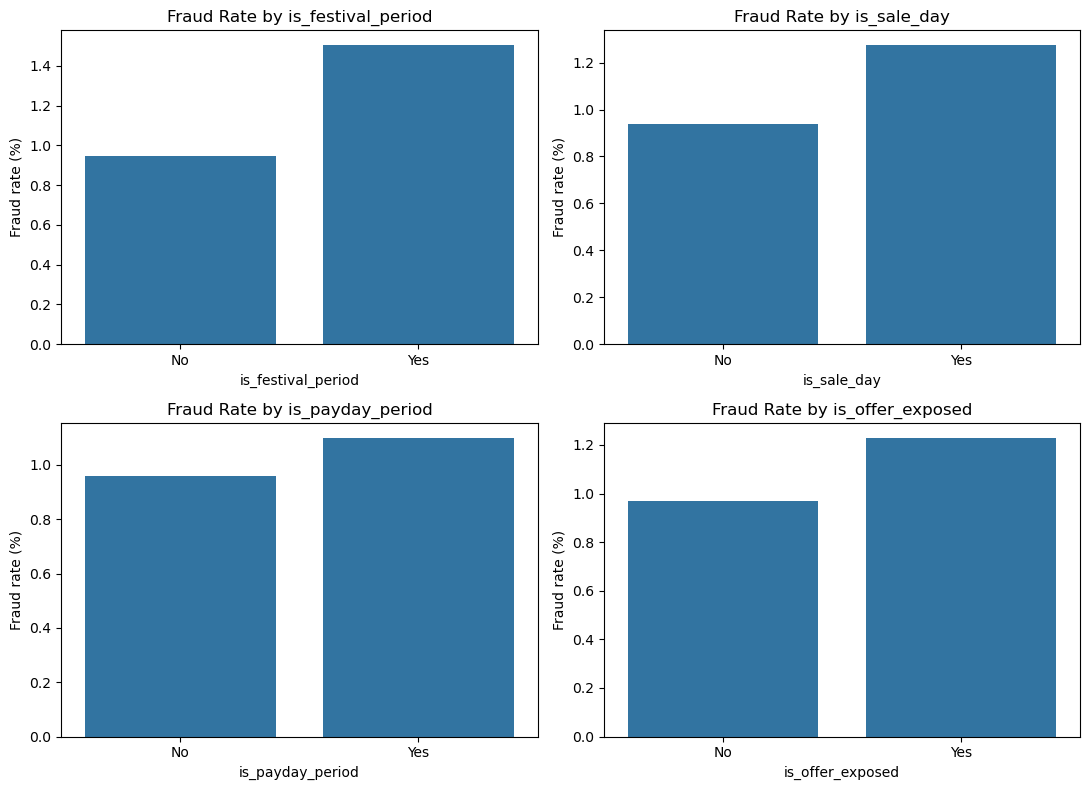

In [8]:

# Analyze fraud rates for selected contextual features
context_features = [
    "is_festival_period",
    "is_sale_day",
    "is_payday_period",
    "is_offer_exposed"
]

for feature in context_features:
    summary = (
        df.groupby(feature)["is_fraud"]
        .agg(["count", "sum", "mean"])
        .rename(columns={
            "count": "Total_transactions",
            "sum": "Fraud_transactions",
            "mean": "Fraud_rate"
        })
    )

    summary["Fraud_rate_pct"] = summary["Fraud_rate"] * 100
    summary.index = summary.index.map({0: "No", 1: "Yes"})

    print(f"\nFraud analysis for {feature}:")
    print(
        summary[
            ["Total_transactions", "Fraud_transactions", "Fraud_rate_pct"]
        ].round(2)
    )

# Plot fraud rates across the contextual features
fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, feature in zip(axes.flatten(), context_features):
    rates = df.groupby(feature)["is_fraud"].mean() * 100

    sns.barplot(
        x=["No", "Yes"],
        y=rates.values,
        ax=ax
    )

    ax.set_title(f"Fraud Rate by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Fraud rate (%)")

plt.tight_layout()
plt.show()


## 9. Analyze Transaction Frequency and Timing Patterns

**Objective:** Compare transaction frequency, distinct payees, and time between transactions for genuine and fraudulent transactions. Use summary statistics and box plots to identify potential behavioral patterns associated with fraud.


--- txns_last_1h ---
         mean  median   std  min  max
Genuine  0.12     0.0  0.43    0    4
Fraud    0.20     0.0  0.55    0    2

--- txns_last_24h ---
         mean  median   std  min  max
Genuine  0.33     0.0  0.67    0    7
Fraud    0.41     0.0  0.74    0    4

--- distinct_payees_last_24h ---
         mean  median   std  min  max
Genuine  0.33     0.0  0.66    0    7
Fraud    0.40     0.0  0.72    0    4

--- minutes_since_last_txn ---
             mean   median       std   min        max
Genuine  12806.72  5351.04  21420.05  0.00  309866.05
Fraud    17947.36  5999.80  30988.80  0.62  279962.33


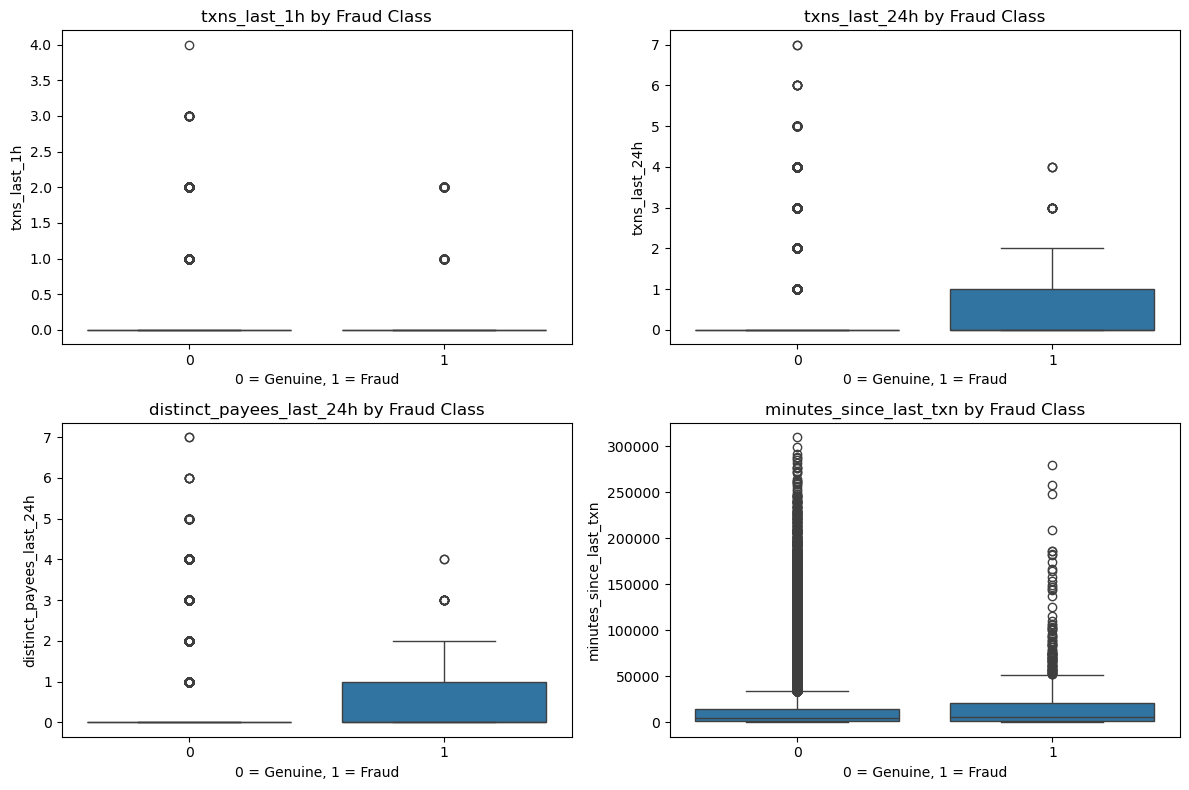

In [9]:
frequency_features = [
    "txns_last_1h",
    "txns_last_24h",
    "distinct_payees_last_24h",
    "minutes_since_last_txn"
]

for feature in frequency_features:
    print(f"\n--- {feature} ---")

    summary = df.groupby("is_fraud")[feature].agg(
        ["mean", "median","std","min", "max"]
    )

    summary.index = ["Genuine", "Fraud"]
    print(summary.round(2))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), frequency_features):
    sns.boxplot(
        data=df,
        x="is_fraud",
        y=feature,
        ax=ax)
    ax.set_title(f"{feature} by Fraud Class")
    ax.set_xlabel("0 = Genuine, 1 = Fraud")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()

## 10. Analyze Transaction Amount and Balance Patterns

**Objective:** Compare historical transaction amounts, amount-to-average ratios, account balances, and balance drain ratios between genuine and fraudulent transactions. Use summary statistics and box plots to identify potential patterns associated with fraud.


--- historical_avg_amount ---
           mean  median     std    min      max
Genuine  701.92  541.07  578.26  24.62  8794.36
Fraud    633.20  482.59  566.40  45.18  6937.72

--- amount_to_avg_ratio ---
         mean  median   std   min    max
Genuine  1.06    0.75  1.08  0.01  31.58
Fraud    2.60    2.61  1.29  0.10  16.52

--- balance_before_inr ---
             mean    median       std     min        max
Genuine  24510.48  13760.36  32271.84   64.56  299471.60
Fraud    26872.77  18922.00  29429.47  401.52  277268.46

--- balance_drain_ratio ---
         mean  median   std  min   max
Genuine  0.12    0.03  0.19  0.0  1.38
Fraud    0.15    0.06  0.20  0.0  1.25


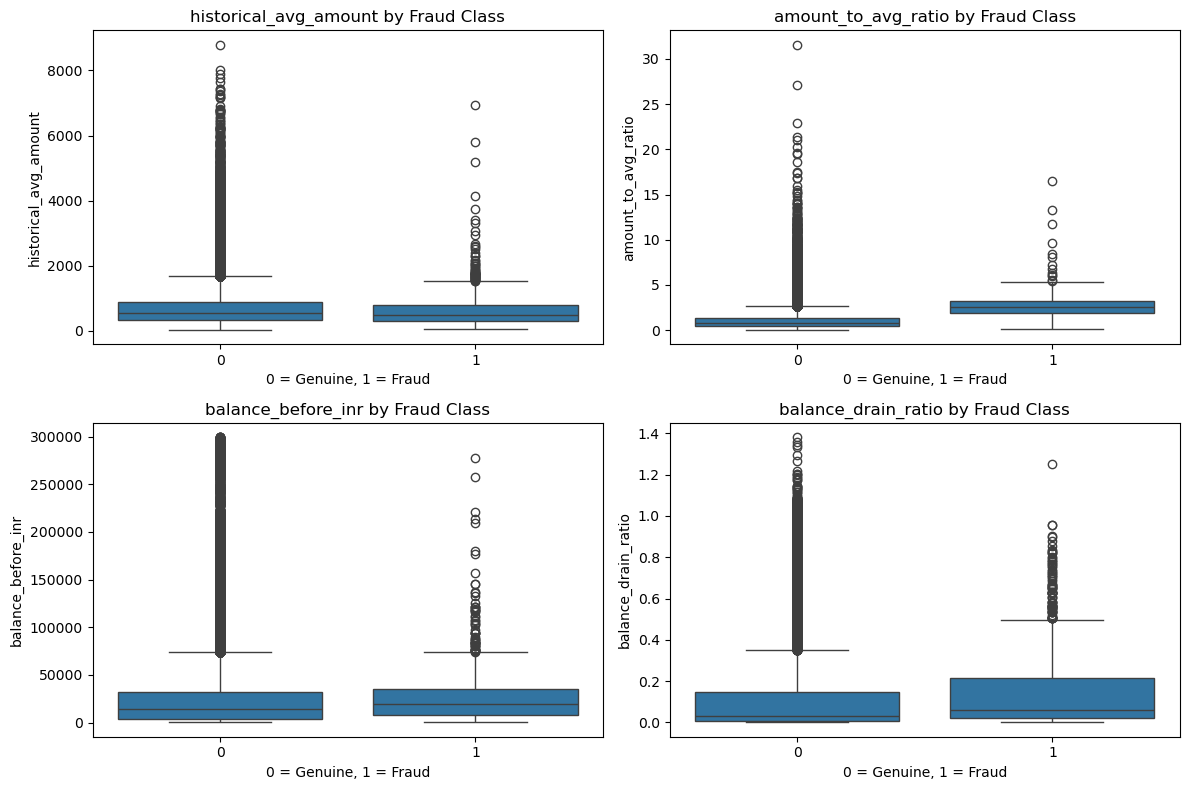

In [10]:

balance_features = [
    "historical_avg_amount",
    "amount_to_avg_ratio",
    "balance_before_inr",
    "balance_drain_ratio"
]

for feature in balance_features:
    print(f"\n--- {feature} ---")

    summary = df.groupby("is_fraud")[feature].agg(
        ["mean", "median", "std", "min", "max"]
    )

    summary.index = ["Genuine", "Fraud"]
    print(summary.round(2))

# Visualize the distributions with boxplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flatten(), balance_features):
    sns.boxplot(
        data=df,
        x="is_fraud",
        y=feature,
        ax=ax
    )

    ax.set_title(f"{feature} by Fraud Class")
    ax.set_xlabel("0 = Genuine, 1 = Fraud")
    ax.set_ylabel(feature)

plt.tight_layout()
plt.show()


## 11. Analyze Fraud Rates Across Categorical Features

**Objective:** Compare transaction counts and fraud rates across payee types, merchant categories, campaigns, offers, disruption types, and location contexts. Identify categories with higher observed fraud rates to explore potential fraud patterns.

In [11]:

categorical_features = [
    "payee_type",
    "merchant_category",
    "festival_name",
    "sale_campaign",
    "offer_type",
    "disruption_type",
    "location_context"
]

for feature in categorical_features:
    print(f"\n{'=' * 55}")
    print(f"Fraud analysis by {feature}")
    print("=" * 55)

    summary = (
        df.groupby(feature, dropna=False)["is_fraud"]
        .agg(
            total_transactions="count",
            fraud_transactions="sum",
            fraud_rate="mean"
        )
        .sort_values("fraud_rate", ascending=False)
    )

    summary["fraud_rate_pct"] = summary["fraud_rate"] * 100

    print(summary.round(2).to_string())



Fraud analysis by payee_type
            total_transactions  fraud_transactions  fraud_rate  fraud_rate_pct
payee_type                                                                    
Merchant                 46729                 476        0.01            1.02
Individual               53271                 524        0.01            0.98

Fraud analysis by merchant_category
                   total_transactions  fraud_transactions  fraud_rate  fraud_rate_pct
merchant_category                                                                    
Utilities                        4318                  58        0.01            1.34
Healthcare                       5018                  65        0.01            1.30
Education                        5311                  55        0.01            1.04
Shopping                         4343                  44        0.01            1.01
Entertainment                    5581                  56        0.01            1.00
Personal       

## 12. Analyze Fraud Rates by Behavioral and Disruption Indicators

**Objective:** Compare fraud rates for transactions involving nighttime activity, weekends, power outages, network disruptions, payment retries, and travel. Examine whether these indicators are associated with different observed fraud rates.

In [12]:

binary_features = [
    "is_night",
    "is_weekend",
    "is_power_outage",
    "is_network_disruption",
    "is_payment_retry",
    "is_traveling"
]

for feature in binary_features:
    summary = (
        df.groupby(feature)["is_fraud"]
        .agg(
            total_transactions="count",
            fraud_transactions="sum",
            fraud_rate="mean"
        )
    )

    summary["fraud_rate_pct"] = summary["fraud_rate"] * 100

    summary.index = summary.index.map({0: "No", 1: "Yes"})

    print(f"\nFraud analysis by {feature}:")
    print(
        summary[
            ["total_transactions", "fraud_transactions", "fraud_rate_pct"]
        ].round(3)
    )



Fraud analysis by is_night:
          total_transactions  fraud_transactions  fraud_rate_pct
is_night                                                        
No                     77618                 339           0.437
Yes                    22382                 661           2.953

Fraud analysis by is_weekend:
            total_transactions  fraud_transactions  fraud_rate_pct
is_weekend                                                        
No                       71452                 711           0.995
Yes                      28548                 289           1.012

Fraud analysis by is_power_outage:
                 total_transactions  fraud_transactions  fraud_rate_pct
is_power_outage                                                        
No                            99884                 999           1.000
Yes                             116                   1           0.862

Fraud analysis by is_network_disruption:
                       total_transactions  fra

## 13. Inspect Timestamps and Identifier Columns

**Objective:** Examine timestamp formats and sample transaction identifiers, including transaction, user, device, and payee IDs. Check the number of unique values to understand these columns before feature selection and preprocessing.

In [13]:

print("Sample timestamps:")
print(df["timestamp"].head(10))

print("\nTimestamp data type:")
print(df["timestamp"].dtype)

print("\nIdentifier samples:")
print(df[["transaction_id", "user_id", "device_id", "payee_id"]].head())

print("\nNumber of unique values:")
for column in ["transaction_id", "user_id", "device_id", "payee_id"]:
    print(f"{column}: {df[column].nunique():,}")


Sample timestamps:
0    2025-04-01 00:07:48
1    2025-04-01 00:09:24
2    2025-04-01 00:12:24
3    2025-04-01 00:15:15
4    2025-04-01 00:21:26
5    2025-04-01 00:26:08
6    2025-04-01 00:28:00
7    2025-04-01 00:37:30
8    2025-04-01 00:42:15
9    2025-04-01 00:45:19
Name: timestamp, dtype: object

Timestamp data type:
object

Identifier samples:
  transaction_id user_id           device_id payee_id
0      TX0085271  U02348  DEV_U02348_PRIMARY   P00939
1      TX0033796  U02134  DEV_U02134_PRIMARY   P00450
2      TX0027901  U02155  DEV_U02155_PRIMARY   P00993
3      TX0017961  U00025  DEV_U00025_PRIMARY   P01618
4      TX0003069  U02065  DEV_U02065_PRIMARY   P02740

Number of unique values:
transaction_id: 100,000
user_id: 5,000
device_id: 8,164
payee_id: 3,000


## 14. Convert Timestamp to Datetime Format

**Objective:** Convert the timestamp column from text into a proper datetime format for time-based analysis. Check the resulting data type and identify any timestamps that failed to convert.

In [14]:

# Convert timestamp from text to datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")

# Display the resulting data type
print("Timestamp data type:", df["timestamp"].dtype)

# Check whether any timestamps failed to convert
print("Invalid timestamps:", df["timestamp"].isna().sum())

# Display the first five converted timestamps
print("\nConverted timestamps:")
print(df["timestamp"].head())


Timestamp data type: datetime64[ns]
Invalid timestamps: 0

Converted timestamps:
0   2025-04-01 00:07:48
1   2025-04-01 00:09:24
2   2025-04-01 00:12:24
3   2025-04-01 00:15:15
4   2025-04-01 00:21:26
Name: timestamp, dtype: datetime64[ns]


## 15. Define Target and Select Model Features

**Objective:** Define `is_fraud` as the target and exclude identifiers, timestamps, and the target column from the initial feature set. Separate the remaining features into categorical and numerical groups and inspect their counts and the target distribution.

In [15]:

# 1. Define the target column
target = "is_fraud"

# 2. Columns that should not be used as initial model features
exclude_columns = [
    "transaction_id",
    "user_id",
    "device_id",
    "payee_id",
    "timestamp",
    target
]

# 3. Create the initial feature list
feature_columns = [
    column for column in df.columns
    if column not in exclude_columns
]

# 4. Identify categorical and numerical features
categorical_columns = df[feature_columns].select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

numerical_columns = df[feature_columns].select_dtypes(
    include=["number"]
).columns.tolist()

# 5. Display the results
print("Target column:", target)
print("Total rows:", len(df))
print("Total initial features:", len(feature_columns))

print("\nCategorical features:", len(categorical_columns))
print(categorical_columns)

print("\nNumerical features:", len(numerical_columns))
print(numerical_columns)

print("\nTarget distribution:")
print(df[target].value_counts())


Target column: is_fraud
Total rows: 100000
Total initial features: 37

Categorical features: 8
['payee_type', 'merchant_category', 'transaction_type', 'festival_name', 'sale_campaign', 'offer_type', 'disruption_type', 'location_context']

Numerical features: 29
['amount_inr', 'transaction_latitude', 'transaction_longitude', 'distance_from_home_km', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_night', 'is_new_device', 'is_new_payee', 'payee_account_age_days', 'txns_last_1h', 'txns_last_24h', 'distinct_payees_last_24h', 'minutes_since_last_txn', 'historical_avg_amount', 'amount_to_avg_ratio', 'balance_before_inr', 'balance_drain_ratio', 'is_festival_period', 'is_sale_day', 'is_payday_period', 'is_offer_exposed', 'is_power_outage', 'is_network_disruption', 'retry_count', 'payment_attempt_count', 'is_payment_retry', 'is_traveling']

Target distribution:
is_fraud
0    99000
1     1000
Name: count, dtype: int64


## 16. Analyze Feature Correlations with Fraud

**Objective:** Measure the correlation between numerical features and the fraud label to identify potentially important variables. Compare selected feature averages for genuine and fraudulent transactions to explore differences in transaction behavior.

In [16]:
# Select numerical candidate features
numeric_features = df[feature_columns].select_dtypes(
    include=["number"]
).columns

#Calculate each feature's correlation with the fraud label
fraud_correlations = (
    df[numeric_features]
    .corrwith(df[target])
    .sort_values(key=abs, ascending=False)
    )

print("Numeric feature correlations with fraud:")
print(fraud_correlations.round(4))

check_columns = [
    "amount_to_avg_ratio",
    "balance_drain_ratio",
    "balance_before_inr",
    "historical_avg_amount",
    "txns_last_1h",
    "txns_last_24h",
    "payment_attempt_count",
    "retry_count"
]

print("\nFeature averages by fraud label:")
print(df.groupby(target)[check_columns].mean().round(3))

Numeric feature correlations with fraud:
distance_from_home_km       0.3225
is_new_device               0.1891
amount_to_avg_ratio         0.1401
is_night                    0.1054
amount_inr                  0.0911
hour_of_day                -0.0773
is_new_payee                0.0609
payee_account_age_days     -0.0244
minutes_since_last_txn      0.0237
balance_drain_ratio         0.0179
txns_last_1h                0.0172
is_festival_period          0.0168
is_sale_day                 0.0129
historical_avg_amount      -0.0118
distinct_payees_last_24h    0.0112
txns_last_24h               0.0112
is_offer_exposed            0.0086
balance_before_inr          0.0073
is_payday_period            0.0063
payment_attempt_count      -0.0028
retry_count                -0.0028
is_payment_retry           -0.0027
day_of_week                 0.0025
transaction_longitude       0.0023
transaction_latitude        0.0015
is_network_disruption      -0.0014
is_weekend                  0.0008
is_traveling  

## 17. Validate Target and Feature Selection

**Objective:** Verify that the target column `is_fraud` is excluded from the input features. Check that transaction identifiers and timestamps are also excluded to help prevent incorrect feature selection before model training.

In [17]:
# Display the target and current input features
print("Target column:", target)

print("\nCurrent feature columns:")
for column in feature_columns:
    print(column)

# Check whether the target accidentally apperas input features
print("\nTarget included in features:", target in feature_columns)

#Check for common identifier and timestamp columns
identifier_columns = [
    "transaction_id",
    "user_id",
    "device_id",
    "payee_id",
    "timestamp"
]

print("\nIdentifier/time columns included in features:")
print([col for col in identifier_columns if col in feature_columns])

Target column: is_fraud

Current feature columns:
payee_type
merchant_category
transaction_type
amount_inr
transaction_latitude
transaction_longitude
distance_from_home_km
hour_of_day
day_of_week
is_weekend
is_night
is_new_device
is_new_payee
payee_account_age_days
txns_last_1h
txns_last_24h
distinct_payees_last_24h
minutes_since_last_txn
historical_avg_amount
amount_to_avg_ratio
balance_before_inr
balance_drain_ratio
is_festival_period
festival_name
is_sale_day
sale_campaign
is_payday_period
is_offer_exposed
offer_type
is_power_outage
is_network_disruption
disruption_type
retry_count
payment_attempt_count
is_payment_retry
is_traveling
location_context

Target included in features: False

Identifier/time columns included in features:
[]


## 18. Separate Input Features and Target Variable

**Objective:** Create `X` containing the selected input features and `y` containing the fraud labels. Verify their shapes and examine the target distribution to confirm the data is ready for splitting and model training.

In [18]:
# Separete input features (X) and target variable (Y)
X = df[feature_columns]
y = df[target]

# Check the shapes of x and y
print("Input features (x) shape:", X.shape)
print("Traget variable (y) shape:", y.shape)

# Check the target distribution
print("\nTarget distribution:")
print(y.value_counts())

print("\nTarget distribution in percentage:")
print((y.value_counts(normalize=True) * 100).round(2))

Input features (x) shape: (100000, 37)
Traget variable (y) shape: (100000,)

Target distribution:
is_fraud
0    99000
1     1000
Name: count, dtype: int64

Target distribution in percentage:
is_fraud
0    99.0
1     1.0
Name: proportion, dtype: float64


## 19. Create Directory for Processed Data

**Objective:** Create the folder for storing processed datasets and related files. Verify that the folder exists before saving the train-test split data and other preprocessing outputs.

In [19]:
from pathlib import Path

#Create a folder for processed dataset
processed_dir = Path(r"E:\UPI_Fraud_Detection\data\processed")
processed_dir.mkdir(parents=True, exist_ok=True)

print("Processed data folder:", processed_dir)
print("Folder ready:", processed_dir.exists())

Processed data folder: E:\UPI_Fraud_Detection\data\processed
Folder ready: True


## 20. Split Data into Training and Testing Sets

**Objective:** Split the dataset into 80% training data and 20% testing data while preserving the fraud-class distribution. Save the four resulting datasets as CSV files and verify the split sizes and fraud counts.

In [20]:
from sklearn.model_selection import train_test_split

#split the data while preserving the fraud ratio
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Save all four datasets
X_train.to_csv(processed_dir / "X_train.csv", index=False)
X_test.to_csv(processed_dir / "X_test.csv", index=False)
y_train.to_csv(processed_dir / "y_train.csv", index=False)
y_test.to_csv(processed_dir / "y_test.csv", index=False)

print("Train/test split saved successfully")

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training fraud cases:", int(y_train.sum()))
print("Testing fraud cases:", int(y_test.sum()))

Train/test split saved successfully
Training rows: 80000
Testing rows: 20000
Training fraud cases: 800
Testing fraud cases: 200


## 21. Identify Categorical and Numerical Features

**Objective:** Separate the training input features into categorical and numerical columns based on their data types. Identify the number and names of each feature group to prepare for preprocessing.

In [21]:
# Identify categorical columns in the training data
categorical_columns = X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

# Identify numerical columns in the training data
numerical_columns = X_train.select_dtypes(
    include=["number","bool"]
).columns.tolist()

print("Number of categorical columns:", len(categorical_columns))
print("Categorical columns:")
print(categorical_columns)

print("\nNumber of numerical columns:", len(numerical_columns))
print("Numerical columns:")
print(numerical_columns)

Number of categorical columns: 8
Categorical columns:
['payee_type', 'merchant_category', 'transaction_type', 'festival_name', 'sale_campaign', 'offer_type', 'disruption_type', 'location_context']

Number of numerical columns: 29
Numerical columns:
['amount_inr', 'transaction_latitude', 'transaction_longitude', 'distance_from_home_km', 'hour_of_day', 'day_of_week', 'is_weekend', 'is_night', 'is_new_device', 'is_new_payee', 'payee_account_age_days', 'txns_last_1h', 'txns_last_24h', 'distinct_payees_last_24h', 'minutes_since_last_txn', 'historical_avg_amount', 'amount_to_avg_ratio', 'balance_before_inr', 'balance_drain_ratio', 'is_festival_period', 'is_sale_day', 'is_payday_period', 'is_offer_exposed', 'is_power_outage', 'is_network_disruption', 'retry_count', 'payment_attempt_count', 'is_payment_retry', 'is_traveling']


## 22. Create the Data Preprocessing Pipeline

**Objective:** Configure a preprocessing pipeline to convert categorical features into numerical format using One-Hot Encoding and standardize numerical features using StandardScaler. This prepares the input data for machine learning model training.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Preprocess categorical and numerical feature separately
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_columns
        )
    ]
)

print("Preprocessing pipeline created successfully.")
print("Categorical features:", len(categorical_columns))
print("Numerical features:", len(numerical_columns))

Preprocessing pipeline created successfully.
Categorical features: 8
Numerical features: 29


## 23. Build the Preprocessing Pipeline

**Objective:** Combine the preprocessing steps into a single scikit-learn pipeline. This makes it easier to apply the same data transformations consistently during training and prediction.

In [23]:
# Create the pereprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor)
    ]
)

print("Preprocessing pipeline is ready.")

Preprocessing pipeline is ready.


## 24. Apply Preprocessing to Training and Testing Data

**Objective:** Fit the preprocessing pipeline on the training data and apply the same transformations to the testing data. Compare the original and processed dataset shapes to verify that the features have been transformed successfully.

In [24]:

# Fit preprocessing on training data and transform it
X_train_processed = preprocessing_pipeline.fit_transform(X_train)

# Transform testing data using the same fitted preprocessing
X_test_processed = preprocessing_pipeline.transform(X_test)

# Display the transformed dataset dimensions
print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

# Check the number of generated features
print("\nTotal features after preprocessing:", X_train_processed.shape[1])

print("\nPreprocessing completed successfully.")


Original training shape: (80000, 37)
Processed training shape: (80000, 69)

Original testing shape: (20000, 37)
Processed testing shape: (20000, 69)

Total features after preprocessing: 69

Preprocessing completed successfully.


## 25. Random Forest Model Training

**Objective:** Train a Random Forest classifier using the preprocessed training data. Use class weighting to help the model handle the imbalance between genuine and fraudulent transactions.

In [25]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(
    X_train_processed,
    y_train.squeeze()
)

print("Random Forest model training completed successfully!")

Random Forest model training completed successfully!


## 26. Generate Baseline Model Predictions

**Objective:** Use the trained Random Forest model to predict whether test transactions are genuine or fraudulent. Count the predicted transactions in each class to understand the model's initial classification results.

In [26]:
# Make predictions on unseen test data
y_pred = rf_model.predict(X_test_processed)

print("Predictions completed succesfully!")
print("Total predictions:", len(y_pred))

import pandas as pd

prediction_counts = pd.Series(y_pred).value_counts().sort_index()

print("\nPredicted transaction counts:")
print(prediction_counts.rename(index={
    0: "Genuine(0)",
    1: "Fraud(1)"
}))

Predictions completed succesfully!
Total predictions: 20000

Predicted transaction counts:
Genuine(0)    19931
Fraud(1)         69
Name: count, dtype: int64


## 27. Import Model Evaluation Metrics

**Objective:** Import the evaluation metrics needed to assess the Random Forest model's performance. These include the confusion matrix, classification report, and accuracy score.

In [27]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

print("Evaluation metrics imported successfully!")

Evaluation metrics imported successfully!


## 28. Evaluate Baseline Model Performance

**Objective:** Evaluate the Random Forest model using the confusion matrix, accuracy, precision, recall, and F1-score. Examine these metrics to understand how well the model identifies genuine and fraudulent transactions.

In [28]:
# Convert actual test labels to one-dimensional format
y_test_1d = y_test.squeeze()

# Calculate the confusion matrix
cm = confusion_matrix(y_test_1d, y_pred)

print("Confusion Matrix:")
print(cm)

# Calculate accuracy
accuracy = accuracy_score(y_test_1d, y_pred)
print(f"\nAccuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

# Display precision, recall, and F1-score
print("\nClassification Report:")
print(
    classification_report(
        y_test_1d,
        y_pred,
        labels=[0, 1],
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

Confusion Matrix:
[[19794     6]
 [  137    63]]

Accuracy: 0.9929 (99.28%)

Classification Report:
              precision    recall  f1-score   support

     Genuine       0.99      1.00      1.00     19800
       Fraud       0.91      0.32      0.47       200

    accuracy                           0.99     20000
   macro avg       0.95      0.66      0.73     20000
weighted avg       0.99      0.99      0.99     20000



## 29. Evaluate Average Precision Score

**Objective:** Calculate the Random Forest model's Average Precision (AP) using predicted fraud probabilities and actual test labels. Use this metric to assess how effectively the model ranks fraudulent transactions, particularly in an imbalanced dataset.

In [29]:
from sklearn.metrics import average_precision_score

# Get the prediction probability of fraud (class 1)

y_prob = rf_model.predict_proba(X_test_processed)[:,1]

# Calculate Average Precision

average_precision = average_precision_score(
    y_test.squeeze(),
    y_prob
)

print(f"Random Forest Avegare Precision: {average_precision:.4f}")

Random Forest Avegare Precision: 0.6620


## 30. Compare Classification Thresholds

**Objective:** Evaluate the Random Forest model at probability thresholds of 0.50, 0.30, and 0.20. Compare the confusion matrix, precision, recall, and F1-score to understand how changing the threshold affects fraud detection.

In [30]:
from sklearn.metrics import(
confusion_matrix,
precision_score,
recall_score,
f1_score
)

# Actual labels from the test dataset
y_test_1d = y_test.squeeze()

# Thresholds we want to compare
thresholds = [0.50, 0.30, 0.20]

for threshold in thresholds:

    # Convert probabilities into fraud/genuine predictions
    y_pred_threshold = (y_prob >= threshold).astype(int)

    # Calculate the confusion matrix
    cm = confusion_matrix(
        y_test_1d,
        y_pred_threshold,
        labels=[0,1]
    )

    # Calculate fraud detection metrics
    precision = precision_score(
        y_test_1d, y_pred_threshold, zero_division=0
    )
    recall = recall_score(
        y_test_1d, y_pred_threshold, zero_division=0
    )

    f1 = f1_score(
        y_test_1d, y_pred_threshold, zero_division=0
    )

    # Display results
    print(f"\nThreshold: {threshold:.2f}")
    print("Confusion Matrix:")
    print(cm)
    print(f"Fraud Precision: {precision:.4f}")
    print(f"Fraud Recall: {recall:.4f}")
    print(f"Fraud F1-score: {f1:.4f}")


Threshold: 0.50
Confusion Matrix:
[[19794     6]
 [  134    66]]
Fraud Precision: 0.9167
Fraud Recall: 0.3300
Fraud F1-score: 0.4853

Threshold: 0.30
Confusion Matrix:
[[19776    24]
 [   97   103]]
Fraud Precision: 0.8110
Fraud Recall: 0.5150
Fraud F1-score: 0.6300

Threshold: 0.20
Confusion Matrix:
[[19746    54]
 [   77   123]]
Fraud Precision: 0.6949
Fraud Recall: 0.6150
Fraud F1-score: 0.6525


## 31. Create Training and Validation Subsets

**Objective:** Split the original training data into a smaller training subset (80%) and a validation subset (20%), while preserving the fraud-class distribution. Check their dimensions and fraud counts to prepare for validation-based model evaluation.

In [31]:
from sklearn.model_selection import train_test_split

# Split the original training data into training and validation subsets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train.squeeze(),
    test_size=0.20,
    random_state=42,
    stratify=y_train.squeeze()
)

# Check the dimensions of each subset
print("training subset shape:", X_fit.shape)
print("validation subset shape:", X_val.shape)

print("\nTraining fraud cases:", int(y_fit.sum()))
print("Validation fraud cases:", int(y_val.sum()))


training subset shape: (64000, 37)
validation subset shape: (16000, 37)

Training fraud cases: 640
Validation fraud cases: 160


## 32. Preprocess Training and Validation Subsets

**Objective:** Create a fresh preprocessing pipeline, fit it only on the training subset, and apply the same transformations to the validation subset. Check the processed shapes to confirm both datasets are ready for model evaluation.

In [32]:
from sklearn.base import clone

# Create a fresh copy of the existing preprocessing pipeline
validation_preprocessor = clone(preprocessing_pipeline)

# Learn preprocessing settings from training data only
X_fit_processed = validation_preprocessor.fit_transform(X_fit)

# Apply the same settings to validation data
X_val_processed = validation_preprocessor.transform(X_val)

# Apply the same settings to validation data
X_val_processed = validation_preprocessor.transform(X_val)

print("Processed training subset:", X_fit_processed.shape)
print("Processed training subset:", X_val_processed.shape)


Processed training subset: (64000, 69)
Processed training subset: (16000, 69)


## 33. Train the Validation Random Forest Model

**Objective:** Train a Random Forest classifier using the preprocessed training subset. Apply class weighting to help address class imbalance before evaluating the model on the separate validation subset.

In [33]:
from sklearn.ensemble import RandomForestClassifier

rf_validation_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_validation_model.fit(X_fit_processed, y_fit)

print("Validation Random Forest training completed!")

Validation Random Forest training completed!



## 34. Generate Validation Fraud Probabilities

**Objective:** Use the trained Validation Random Forest model to calculate the probability of fraud for each transaction in the validation dataset. These probabilities will help us compare different classification thresholds and select a suitable threshold based on validation performance.


In [34]:
# Generate fraud probabilities for the validation dataset
y_val_prob = rf_validation_model.predict_proba(X_val_processed)[:,1]

print("Validation fraud probabilities generated successfully")
print("Number of validation predictions:", len(y_val_prob))
print("First 10 fraud probabilities:", y_val_prob[:10])

Validation fraud probabilities generated successfully
Number of validation predictions: 16000
First 10 fraud probabilities: [0.01 0.01 0.   0.02 0.   0.   0.   0.   0.   0.  ]



## 35. Compare Classification Thresholds on Validation Data

**Objective:** Evaluate the validation model at different probability thresholds using precision, recall, and F1-score. This will help us select a suitable fraud detection threshold without using the final test set.


In [35]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

# Convert validation labels into a one-dimensional array

y_val_1d = y_val.squeeze()

# Define the thresholds to compare
thresholds = [0.50, 0.30, 0.20]

# Evaluate the model at each threshold
for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    cm = confusion_matrix(y_val_1d, y_val_pred, labels=[0,1])
    precision = precision_score(y_val_1d, y_val_pred, zero_division=0)
    recall = recall_score(y_val_1d, y_val_pred, zero_division=0)
    f1 = f1_score(y_val_1d, y_val_pred, zero_division=0)

    print(f"\nThreshold: {threshold:.2f}")
    print("Confusion Matrix:")
    print(cm)
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"f1_score: {f1:.4f}")


Threshold: 0.50
Confusion Matrix:
[[15832     8]
 [  107    53]]
Precision: 0.8689
Recall: 0.3312
f1_score: 0.4796

Threshold: 0.30
Confusion Matrix:
[[15815    25]
 [   71    89]]
Precision: 0.7807
Recall: 0.5563
f1_score: 0.6496

Threshold: 0.20
Confusion Matrix:
[[15788    52]
 [   57   103]]
Precision: 0.6645
Recall: 0.6438
f1_score: 0.6540


## 36. Select the Best Classification Threshold

**Objective:** Select the threshold with the highest F1-score from the validation results. Record the selected threshold for final model evaluation while keeping the original test dataset untouched.

In [36]:
from sklearn.metrics import precision_score, recall_score, f1_score

# Define the thresholds evaluated in Heading 35
threshold = [0.50, 0.30, 0.20]

# Store the evaulation results for each threshold
threshold_results = []

for threshold in thresholds:
    y_val_pred = (y_val_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision" : precision_score(
            y_val_1d, y_val_pred, zero_division=0
        ),
        "recall" : recall_score(
            y_val_1d, y_val_pred, zero_division=0
        ),
        "f1_score": f1_score(
            y_val_1d, y_val_pred, zero_division=0
        )
    })

# Select the threshold with the highest F1-score
best_result = max(
    threshold_results,
    key=lambda result: result["f1_score"]
)

selected_threshold = best_result["threshold"]

print("selected threshold:", selected_threshold)
print(f"Validation Precision: {best_result['precision']:.4f}")
print(f"Validation Recall:    {best_result['recall']:.4f}")
print(f"Validation F1-score:  {best_result['f1_score']:.4f}")
      


selected threshold: 0.2
Validation Precision: 0.6645
Validation Recall:    0.6438
Validation F1-score:  0.6540


## 37. Train the Final Random Forest Model

**Objective:** Train the final Random Forest model using the complete 80,000-row training dataset. Fit the preprocessing pipeline on the full training data and prepare the model for final evaluation on the untouched test dataset.

In [5]:
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier

# create a fresh copy of the preprocessing pipleine
final_preprocessor = clone(preprocessing_pipeline)

# Fit preprocessing on the complete training data
X_train_final_processed = final_preprocessor.fit_transform(X_train)

# Apply the same preprocessing to the untouch test data
X_test_final_processed = final_preprocessor.transform(X_test)

# Initialize the final Random forest Model
final_rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Train the model using all training records
final_rf_model.fit(
    X_train_final_processed,
    y_train.squeeze()
)

print("Final Random Forest model trained successfully")
print("Training data shape:", X_train_final_processed.shape)
print("Test data shape:", X_test_final_processed.shape)
print("Selected Classification threshold:", selected_threshold)

Final Random Forest model trained successfully
Training data shape: (80000, 69)
Test data shape: (20000, 69)
Selected Classification threshold: 0.2


## 38. Evaluate the Final Model on Test Data
Objective: Evaluate the final Random Forest model on the 20,000 unseen transactions using the selected threshold of 0.20 and measure its fraud detection performance.

In [6]:
from sklearn.metrics import (
confusion_matrix,
classification_report,
accuracy_score,
precision_score,
recall_score,
f1_score
)

# step1: Generate fraud probabilities for the test data
y_test_prob = final_rf_model.predict_proba(
    X_test_final_processed
)[:,1]

# step 2: Apply the selected threshold
y_test_pred = (y_test_prob >= selected_threshold).astype(int)

# Step3: Display the confusion matrix
cm = confusion_matrix(
    y_test.squeeze(),
    y_test_pred,
    labels=[0,1]
)

print("Confusion Matrix:")
print(cm)

# Step4: Display the detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test.squeeze(),
    y_test_pred,
    target_names=["Genuine", "Fraud"],
    zero_division=0
))

Confusion Matrix:
[[19746    54]
 [   77   123]]

Classification Report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     19800
       Fraud       0.69      0.61      0.65       200

    accuracy                           0.99     20000
   macro avg       0.85      0.81      0.82     20000
weighted avg       0.99      0.99      0.99     20000



## Heading 39: Analyze Misclassified Transactions
Objective: Identify the genuine transactions incorrectly flagged as fraud and the fraud tranacations the model missed. This will help us understand where our random Forest model is making mistakes before deciding how to improve it.

In [39]:
import pandas as pd
import numpy as np

# Step1: Create a dataframe with actual and predicted results
error_analysis = pd.DataFrame({
    "Actual": y_test.squeeze().to_numpy(),
    "Predicted": y_test_pred,
    "Fraud_Probability": y_test_prob
})

# step 2 : Identify misclassified tranactions
error_analysis["Result"] = np.where(
    error_analysis["Actual"] == error_analysis["Predicted"],
    "Correct",
    "Incorrect"
)

# step 3: Separate false positives and false negatives
false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
]

false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) & 
    (error_analysis["Predicted"] == 0)
]

# Step 5: Display examples of each type of error
print("\nFalse Positive Examples:")
display(false_positives.head(5))

print("\nFalse Negative examples:")
display(false_negatives.head(5))


False Positive Examples:


,Actual,Predicted,Fraud_Probability,Result
15,0,1,0.21,Incorrect
186,0,1,0.28,Incorrect
587,0,1,0.24,Incorrect
676,0,1,0.22,Incorrect
703,0,1,0.27,Incorrect



False Negative examples:


,Actual,Predicted,Fraud_Probability,Result
223,1,0,0.03,Incorrect
443,1,0,0.00,Incorrect
686,1,0,0.17,Incorrect
805,1,0,0.00,Incorrect
1065,1,0,0.00,Incorrect


## Heading 40: Analyze Feature importance
Objective: Identify which inpute features contribute most to the Random Forest Model's Fraud Predictions.
This will help us understand which transaction characteristics the model relies on when classifying tranactions as genuine or fraudulent.

Top 15 Most Important Features:


,Feature,Importance
56,numerical__amount_to_avg_ratio,0.208855
43,numerical__distance_from_home_km,0.122012
40,numerical__amount_inr,0.070186
44,numerical__hour_of_day,0.069580
47,numerical__is_night,0.056051
13,categorical__transaction_type_Collect_Request,0.052536
14,categorical__transaction_type_Pay,0.051137
49,numerical__is_new_payee,0.050642
48,numerical__is_new_device,0.050032
58,numerical__balance_drain_ratio,0.032216


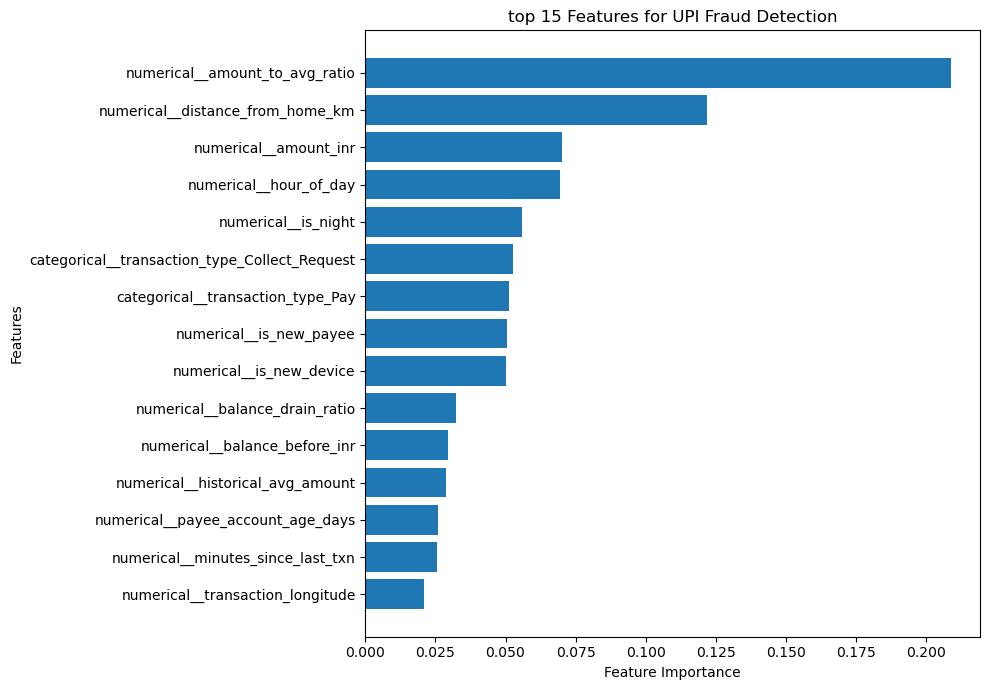

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Step1 : get feature importance scores from the trained model
feature_importances = final_rf_model.feature_importances_

# Step 2: Get the feature names after preprocessing
feature_names = final_preprocessor.get_feature_names_out()

# Step 3: Create a dataframe of feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

# step 4: Sort deatures from most important to least important
importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Step 5 : Display the top 15 most important features
print("Top 15 Most Important Features:")
display(importance_df.head(15))

# Step 6: Visualize the top 15 features
top_features = importance_df.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10,7))
plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.title("top 15 Features for UPI Fraud Detection")
plt.tight_layout()
plt.show()

## Heading 41: Analyze the Top Important Features
Objective: Examine the importance scores of the top 10 features and calculate their combined contribution to the random Forest nmodel's feature importance scores. this will help us understand how concentrated the model's reliance is on a small group of features.

In [10]:
# Step 1: Select the top 10 most important features
top_10_features = importance_df.head(10).copy()

# Step 2: Calculate their combined importance score
top_10_total_importance = top_10_features["Importance"].sum()

# Step 3: Display the top 10 features
print("Top 10 Most important Features:")
display(top_10_features)

# Step 4: Display the combined importance score
print(
    "\nCombined importance of top 10 features:",
    round(top_10_total_importance, 4)
)

# Step 5: Calculate the importance share of each feature
top_10_features["Importance_Percentage"] = (
    top_10_features["Importance"] * 100
)

Top 10 Most important Features:


,Feature,Importance
56,numerical__amount_to_avg_ratio,0.208855
43,numerical__distance_from_home_km,0.122012
40,numerical__amount_inr,0.070186
44,numerical__hour_of_day,0.069580
47,numerical__is_night,0.056051
13,categorical__transaction_type_Collect_Request,0.052536
14,categorical__transaction_type_Pay,0.051137
49,numerical__is_new_payee,0.050642
48,numerical__is_new_device,0.050032
58,numerical__balance_drain_ratio,0.032216



Combined importance of top 10 features: 0.7632


## Heading 42: Precision-Recall Curve
Objective: Evaluate how well our Random Forest model identifies fraudulent UPI tranactions by examining the relationship between precision and recall at different classification thresholds.

Average Precision (AP): 0.662


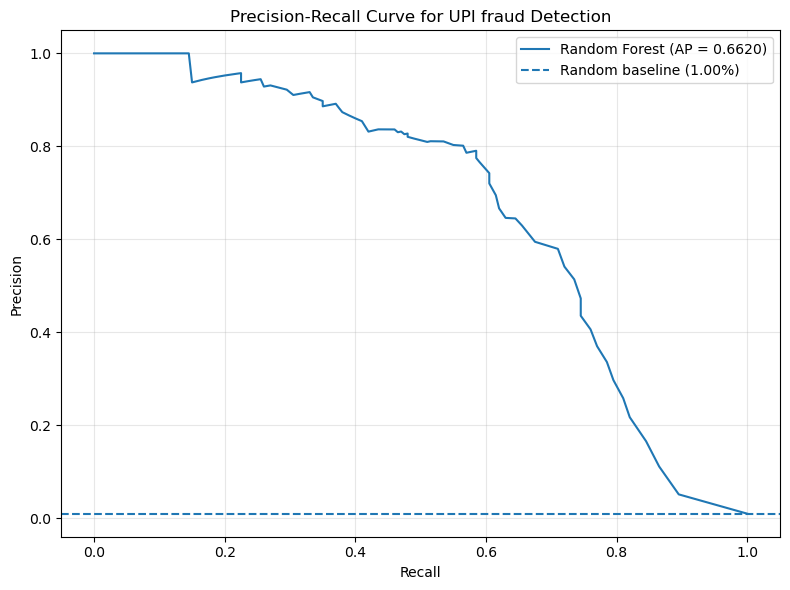

In [11]:
# Step1: Import the required evaluation tools
import matplotlib.pyplot as plt
from sklearn.metrics import (
precision_recall_curve,
average_precision_score
)

# Step 2: Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = (
    precision_recall_curve(
        y_test.squeeze(),
        y_test_prob
    )
)

# Step 3: Calculate precision and recall at different thresholds
average_precision = average_precision_score(
    y_test.squeeze(),
    y_test_prob
)

print("Average Precision (AP):", round(average_precision, 4))

# Step 4: Plot the Precision-Reacll curve
plt.figure(figsize=(8,6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Random Forest (AP = {average_precision:.4f})"
)

# Step 5: Add the baseline for random predictions
fraud_rate = y_test.squeeze().mean()

plt.axhline(
    y=fraud_rate,
    linestyle="--",
    label=f"Random baseline ({fraud_rate:.2%})"
)

# Step 6: Add labels and display the chart
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve for UPI fraud Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Heading 43: ROC Curve and AUC
Objective: Evaluate how well our Random Forest model distinguishes fraudulent UPI transactions from genuine transactions across different classification thresholds.

ROC-AUC Score: 0.931


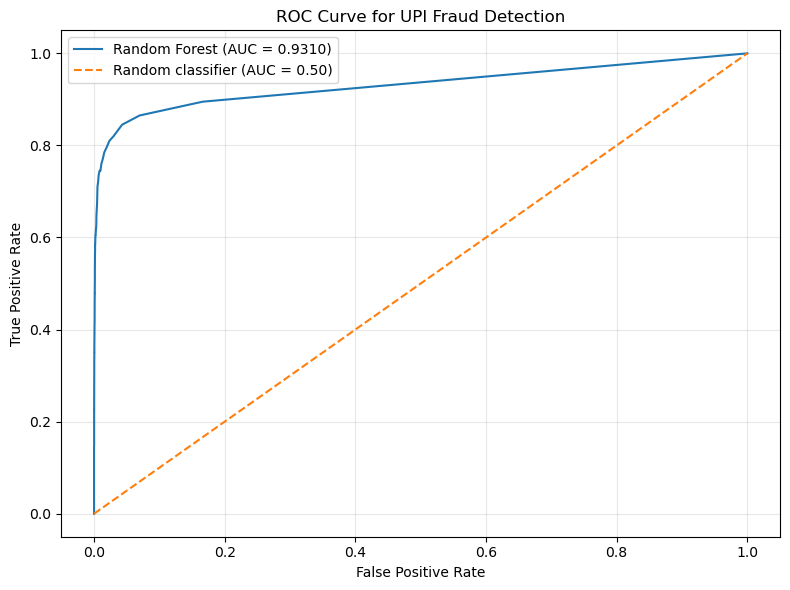

In [12]:
# Step 1: Import the required evaluation tools
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Step 2: Calculate the ROC curve points
fpr, tpr, thresholds_roc = roc_curve(
    y_test.squeeze(),
    y_test_prob
)

# Step 3: Calculate the Area Under the ROC Curve (AUC)
roc_auc = roc_auc_score(
    y_test.squeeze(),
    y_test_prob
)

print("ROC-AUC Score:", round(roc_auc, 4))

# Step 4: Plot the ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc:.4f})"
)

# Step 5: Add the random-classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier (AUC = 0.50)"
)

# Step 6: Add labels and display the chart
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve for UPI Fraud Detection")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Heading 44: Compare Evaluation Metrics
Objective: Bring together the main evaluation metrics of our final Random forest model to understand its performance on UPI fraud detection. 

In [13]:
import pandas as pd
from sklearn.metrics import(
accuracy_score,
precision_score,
recall_score,
f1_score,
average_precision_score,
roc_auc_score
)

# Step 1: Calculate the evaluation metrics
y_test_actual = y_test.squeeze()

metrics_comparison = pd.DataFrame({
        "Metrics": [
        "Accuracy",
        "precision",
        "Recall",
        "F1-Score",
        "Average Precision",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test_actual, y_test_pred),
        precision_score(y_test_actual, y_test_pred, zero_division=0),
        recall_score(y_test_actual, y_test_pred, zero_division=0),
        f1_score(y_test_actual, y_test_pred, zero_division=0),
        average_precision_score(y_test_actual, y_test_prob),
        roc_auc_score(y_test_actual, y_test_prob)
    ]
})

# step 2: Round the score for readability
metrics_comparison["Score"] = metrics_comparison["Score"].round(4)

# Step 3: Display the comparison table
print("Final random Forest Evaluation Metrics")
display(metrics_comparison)

Final random Forest Evaluation Metrics


,Metrics,Score
0,Accuracy,0.9934
1,precision,0.6949
2,Recall,0.6150
3,F1-Score,0.6525
4,Average Precision,0.6620
5,ROC-AUC,0.9310


## Heading 45 Save the selected Random Forest Model and Artifacts.
The following five components are saved:
1. Trained random Forest Model.
2. Fitted Preprocessing Pipeline.
3. Selected Classification Threshold (0.20).
4. Feature column names and their order.
5. Model Evaluation Results.

In [14]:

import os
import joblib
import pandas as pd

# Step 1: Create model directory
model_dir = r"E:\UPI_Fraud_Detection\models"
os.makedirs(model_dir, exist_ok=True)

# Step 2: Save the FINAL Random Forest model
joblib.dump(
    final_rf_model,
    os.path.join(model_dir, "random_forest_model.pkl")
)

# Step 3: Save the FINAL preprocessing pipeline
joblib.dump(
    final_preprocessor,
    os.path.join(model_dir, "preprocessor.pkl")
)

# Step 4: Save the selected threshold
joblib.dump(
    selected_threshold,
    os.path.join(model_dir, "threshold.pkl")
)

# Step 5: Save feature column names
feature_columns = X_train.columns.tolist()

joblib.dump(
    feature_columns,
    os.path.join(model_dir, "feature_columns.pkl")
)

# Step 6: Prepare final test evaluation results
evaluation_results = metrics_comparison.copy()

evaluation_results.columns = ["Metric", "Value"]

# Add classification threshold
evaluation_results = pd.concat([
    evaluation_results,
    pd.DataFrame({
        "Metric": ["Classification Threshold"],
        "Value": [selected_threshold]
    })
], ignore_index=True)

# Step 7: Save evaluation results
evaluation_results.to_csv(
    os.path.join(model_dir, "evaluation_results.csv"),
    index=False
)

print("Final Random Forest artifacts saved successfully!")
print("\nFinal Evaluation Results:")
display(evaluation_results)

print("\nSaved Files:")
for file in os.listdir(model_dir):
    print("-", file)


Final Random Forest artifacts saved successfully!

Final Evaluation Results:


,Metric,Value
0,Accuracy,0.9934
1,precision,0.6949
2,Recall,0.6150
3,F1-Score,0.6525
4,Average Precision,0.6620
5,ROC-AUC,0.9310
6,Classification Threshold,0.2000



Saved Files:
- evaluation_results.csv
- feature_columns.pkl
- preprocessor.pkl
- random_forest_model.pkl
- svm_complete_checkpoint.pkl
- svm_confusion_matrix.csv
- svm_feature_columns.pkl
- svm_final_test_results.csv
- svm_model.pkl
- svm_preprocessor.pkl
- svm_threshold.pkl
- svm_validation_results.csv
- threshold.pkl


## Heading 46 – Load Saved Random Forest Model and Artifacts
If saved load this cell

In [1]:
import os
import joblib
import pandas as pd

# Define model directory
model_dir = r"E:\UPI_Fraud_Detection\models"

# Load saved Random Forest model
rf_model_loaded = joblib.load(
    os.path.join(model_dir, "random_forest_model.pkl")
)

# Load preprocessing object
preprocessor_loaded = joblib.load(
    os.path.join(model_dir, "preprocessor.pkl")
)

# Load selected classification threshold
rf_threshold_loaded = joblib.load(
    os.path.join(model_dir, "threshold.pkl")
)

# Load feature column names
feature_columns_loaded = joblib.load(
    os.path.join(model_dir, "feature_columns.pkl")
)

# Load evaluation results
rf_evaluation_results = pd.read_csv(
    os.path.join(model_dir, "evaluation_results.csv")
)

print("Random Forest model and artifacts loaded successfully!")

print("\nSelected Threshold:", rf_threshold_loaded)
print("\nNumber of Features:", len(feature_columns_loaded))

print("\nSaved Evaluation Results:")
print(rf_evaluation_results)

Random Forest model and artifacts loaded successfully!

Selected Threshold: 0.2

Number of Features: 37

Saved Evaluation Results:
                     Metric   Value
0                  Accuracy  0.9934
1                 precision  0.6949
2                    Recall  0.6150
3                  F1-Score  0.6525
4         Average Precision  0.6620
5                   ROC-AUC  0.9310
6  Classification Threshold  0.2000


In [2]:
import pandas as pd
from sklearn.pipeline import Pipeline

# Load the saved training and testing datasets
processed_dir = r"E:\UPI_Fraud_Detection\data\processed"

X_train = pd.read_csv(processed_dir + r"\X_train.csv")
X_test = pd.read_csv(processed_dir + r"\X_test.csv")

y_train = pd.read_csv(processed_dir + r"\y_train.csv").squeeze()
y_test = pd.read_csv(processed_dir + r"\y_test.csv").squeeze()

# Reconstruct the preprocessing pipeline
preprocessing_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor_loaded)
    ]
)

# Restore the selected threshold
selected_threshold = rf_threshold_loaded

print("Data and settings restored successfully!")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Selected threshold:", selected_threshold)

Data and settings restored successfully!
X_train: (80000, 37)
X_test: (20000, 37)
Selected threshold: 0.2


## Heading 47: Train the SVM Model
Objective: In this step train Support Vector Machine (SVM) Model using linearSVC. Class weighting is applied to handle the imbalance between genuine and fraudulent tranacations. The Model is trained on the preprocessed training data and evaluated on the validation data.

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone

# Recreate the training and validation split
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train.squeeze(),
    test_size=0.20,
    random_state=42,
    stratify=y_train.squeeze()
)

# Create a fresh preprocessing pipeline
validation_preprocessor = clone(preprocessing_pipeline)

# Fit on training subset and transform validation subset
X_fit_processed = validation_preprocessor.fit_transform(X_fit)
X_val_processed = validation_preprocessor.transform(X_val)

print("SVM training and validation data restored successfully!")
print("Training subset:", X_fit_processed.shape)
print("Validation subset:", X_val_processed.shape)
print("Training fraud cases:", int(y_fit.sum()))
print("Validation fraud cases:", int(y_val.sum()))

SVM training and validation data restored successfully!
Training subset: (64000, 69)
Validation subset: (16000, 69)
Training fraud cases: 640
Validation fraud cases: 160


In [20]:
from sklearn.svm import LinearSVC
from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
average_precision_score,
confusion_matrix
)

# Initialize SVM Model
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

# Train the model
svm_model.fit(X_fit_processed, y_fit.squeeze())

# predict validation data
y_svm_val_pred = svm_model.predict(X_val_processed)

# Get decision scores for ranking evaluation
y_sum_val_scores = svm_model.decision_function(X_val_processed)

# evaluate the model
print("SVM Model Evaluation")

print("Accuracy:", accuracy_score(y_val, y_svm_val_pred))
print("Precision:", precision_score(y_val, y_svm_val_pred))
print("Recall:", recall_score(y_val, y_svm_val_pred))
print("F1-Score:", f1_score(y_val, y_svm_val_pred))
print("Average Precision:", average_precision_score(y_val, y_svm_val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_svm_val_pred))

SVM Model Evaluation
Accuracy: 0.9044375
Precision: 0.08489993935718618
Recall: 0.875
F1-Score: 0.15478164731896074
Average Precision: 0.0755374469375379

Confusion Matrix:
[[14331  1509]
 [   20   140]]


In [22]:
from sklearn.svm import LinearSVC

# Create and train the SVM model
svm_model = LinearSVC(
    class_weight="balanced",
    random_state=42,
    max_iter=5000
)

svm_model.fit(X_fit_processed, y_fit.squeeze())

# Generate validation decision scores
y_svm_val_scores = svm_model.decision_function(X_val_processed)

print("SVM training completed!")
print("Validation scores:", len(y_svm_val_scores))

SVM training completed!
Validation scores: 16000


## Heading 48: SVM Threshold Tuning
Objective: To identify the threshold that provides the best F1-Score by balancing Precision and Recall.
The optimized threshold is then used for final SVM classification and evaluation.

In [23]:
import numpy as np
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    average_precision_score
)

# Calculate precision and recall at different thresholds
precision_values, recall_values, thresholds = precision_recall_curve(
    y_val,
    y_svm_val_scores
)

# Calculate F1-score for each threshold
f1_values = (
    2 * precision_values[:-1] * recall_values[:-1]
    / (precision_values[:-1] + recall_values[:-1] + 1e-10)
)

# Find the threshold with the highest F1-score
best_index = np.argmax(f1_values)
best_svm_threshold = thresholds[best_index]

# Generate predictions using the selected threshold
y_svm_tuned_pred = (
    y_svm_val_scores >= best_svm_threshold
).astype(int)

# Display evaluation results
print("Best SVM Threshold:", best_svm_threshold)

print("\nSVM Evaluation After Threshold Tuning")
print("Precision:", precision_score(y_val, y_svm_tuned_pred))
print("Recall:", recall_score(y_val, y_svm_tuned_pred))
print("F1-Score:", f1_score(y_val, y_svm_tuned_pred))
print("Average Precision:", average_precision_score(y_val, y_svm_val_scores))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_svm_tuned_pred))

Best SVM Threshold: 0.9520998434772847

SVM Evaluation After Threshold Tuning
Precision: 0.31451612903225806
Recall: 0.4875
F1-Score: 0.38235294117647056
Average Precision: 0.3327371967733012

Confusion Matrix:
[[15670   170]
 [   82    78]]


## Heading 49: Save SVM Model and Artifacts

The saved artifacts include:
- Trained SVM model
- Optimized classification threshold
- Fitted preprocessing transformer
- Original feature column names
- SVM validation evaluation results

In [55]:
import os
import joblib
import pandas as pd
import numpy as np

from sklearn.metrics import (
accuracy_score,
precision_score,
recall_score,
f1_score,
average_precision_score
)

# Create Model Directory
model_dir = r"E:\UPI_Fraud_Detection\models"
os.makedirs(model_dir, exist_ok=True)

# Save trained SVM Model
joblib.dump(
    svm_model,
    os.path.join(model_dir, "svm_model.pkl")
)

# Save optimized classification threshold
joblib.dump(
    best_svm_threshold,
    os.path.join(model_dir, "svm_threshold.pkl")
)

# Save fitted preprocessing transformer
joblib.dump(
    preprocessor,
    os.path.join(model_dir, "svm_preprocessor.pkl")
)

# Save original feature columns
feature_columns = X_fit.columns.tolist()

joblib.dump(
    feature_columns,
    os.path.join(model_dir, "svm_feature_columns.pkl")
)

# calculate tuned validation metrics
y_val_actual = np.asarray(y_val).ravel()

svm_validation_accuracy = accuracy_score(
    y_val_actual, y_svm_tuned_pred
)

svm_validation_precision = precision_score(
    y_val_actual, y_svm_tuned_pred, zero_division=0
)

svm_validation_recall = recall_score(
    y_val_actual, y_svm_tuned_pred, zero_division=0
)

svm_validation_f1 = f1_score(
    y_val_actual, y_svm_tuned_pred, zero_division=0
)


svm_validation_ap = average_precision_score(
    y_val_actual, y_svm_val_scores
)

# Store val;idation results
svm_validation_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Average Precision",
        "Classification Threshold"
    ],
    "Value": [
        svm_validation_accuracy,
        svm_validation_precision,
        svm_validation_recall,
        svm_validation_f1,
        svm_validation_ap,
        best_svm_threshold
    ]
})

# Save validation results
svm_validation_results.to_csv(
    os.path.join(model_dir, "svm_validation_results.csv"),
    index=False
)

print("SVM Model and Artifacts saved successfully")

print("\nSelected SVm Threshold:", best_svm_threshold)

print("\nValidation Results:")
print(svm_validation_results)

print("\nSaved Files:")
for file in [
    "svm_model.pkl",
    "svm_threshold.pkl",
    "svm_preprocessor.pkl",
    "svm_feature_columns.pkl",
    "svm_validation_results.csv"
]:
    print("-", file)

SVM Model and Artifacts saved successfully

Selected SVm Threshold: 0.9520998434772847

Validation Results:
                     Metric     Value
0                  Accuracy  0.984250
1                 Precision  0.314516
2                    Recall  0.487500
3                  F1-score  0.382353
4         Average Precision  0.332737
5  Classification Threshold  0.952100

Saved Files:
- svm_model.pkl
- svm_threshold.pkl
- svm_preprocessor.pkl
- svm_feature_columns.pkl
- svm_validation_results.csv


## Heading 50: SVM final Testing
Objective: Evaluate the tuned SVM Model on the 20,000 record test dataset using the optimizer threshold selected during validation.

In [61]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix
)

import numpy as np

# Align test features with training feature columns
X_test_aligned = X_test[feature_columns]

# Transform test data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test_aligned)

# Generate SVM decision scores
y_svm_test_scores = svm_model.decision_function(
    X_test_processed
)

# Apply optimized classification threshold
y_svm_test_pred = (
    y_svm_test_scores >= best_svm_threshold
).astype(int)

# Prepare actual test labels
y_test_actual = np.asarray(y_test).ravel()

# Calculate evaluation metrics
svm_test_accuracy = accuracy_score(
    y_test_actual, y_svm_test_pred
)

svm_test_precision = precision_score(
    y_test_actual, y_svm_test_pred, zero_division=0
)

svm_test_recall = recall_score(
    y_test_actual, y_svm_test_pred, zero_division=0
)

svm_test_f1 = f1_score(
    y_test_actual, y_svm_test_pred, zero_division=0
)

svm_test_ap = average_precision_score(
    y_test_actual, y_svm_test_scores
)

svm_test_roc_auc = roc_auc_score(
    y_test_actual, y_svm_test_scores
)

# Generate confusion matrix
svm_test_cm = confusion_matrix(
    y_test_actual, y_svm_test_pred
)

# Display results
print("SVM FINAL TEST RESULTS")
print("-" * 40)

print(f"Accuracy:          {svm_test_accuracy:.4f}")
print(f"Precision:         {svm_test_precision:.4f}")
print(f"Recall:            {svm_test_recall:.4f}")
print(f"F1-Score:          {svm_test_f1:.4f}")
print(f"Average Precision: {svm_test_ap:.4f}")
print(f"ROC-AUC:           {svm_test_roc_auc:.4f}")

print("\nClassification Threshold:", best_svm_threshold)

print("\nConfusion Matrix:")
print(svm_test_cm)

SVM FINAL TEST RESULTS
----------------------------------------
Accuracy:          0.9849
Precision:         0.3455
Recall:            0.5700
F1-Score:          0.4302
Average Precision: 0.3896
ROC-AUC:           0.9178

Classification Threshold: 0.9520998434772847

Confusion Matrix:
[[19584   216]
 [   86   114]]


## Heading 51: Save Final SVM Test Results
Objective: Save the file SVM Test evaluation metrics and confusion matrix as csv files for future comparison and project documentation.

In [65]:
# Create final SVM test results Dataframe
svm_final_results = pd.DataFrame({
    "Metrics": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Average Precision",
        "ROC-AUC",
        "Classification Threshold"
    ],
    "Value": [
        svm_test_accuracy,
        svm_test_precision,
        svm_test_recall,
        svm_test_f1,
        svm_test_ap,
        svm_test_roc_auc,
        best_svm_threshold
    ]
})


# Save final evaluation results
svm_final_results.to_csv(
    os.path.join(model_dir, "svm_final_test_results.csv"),
    index=False
)

# Create confusion matrix DataFrame
svm_confusion_df = pd.DataFrame(
    svm_test_cm,
    index=["Actual Genuine", "Actual Fraud"],
    columns=["Predicted Genuine", "Predicted Fraud"]
)

# Save confusion matrix
svm_confusion_df.to_csv(
    os.path.join(model_dir, "svm_confusion_matrix.csv")
)

print("SVM final test results saved successfully")

print("\nFinal Test Results:")
print(svm_final_results)

print("\nConfusion Matrix:")
print(svm_confusion_df)

print("\nSaved File:")
print("- svm_final_test_results.csv")
print("- svm_confusion_matrix.csv")

SVM final test results saved successfully

Final Test Results:
                    Metrics     Value
0                  Accuracy  0.984900
1                 Precision  0.345455
2                    Recall  0.570000
3                  F1-Score  0.430189
4         Average Precision  0.389640
5                   ROC-AUC  0.917799
6  Classification Threshold  0.952100

Confusion Matrix:
                Predicted Genuine  Predicted Fraud
Actual Genuine              19584              216
Actual Fraud                   86              114

Saved File:
- svm_final_test_results.csv
- svm_confusion_matrix.csv


## Heading: 52:  Save Complete SVM and Dataset Checkpoint
Objective: Save all important SVM model artifacts, processed datasets, labels, preprocessing information, and evaluation results into a single checkpoint file. This checkpoint will allow us to restore the complete SVM workflow after restarting Jupyter.

In [66]:
# Create complete project checkpoint

svm_complete_checkpoint = {

    # 1. SVM Model Artifacts
    "svm_model": svm_model,
    "best_svm_threshold": best_svm_threshold,
    "preprocessor": preprocessor,
    "feature_columns": feature_columns,

    # 2. Processed Feature Datasets
    "X_fit_processed": X_fit_processed,
    "X_val_processed": X_val_processed,
    "X_test_processed": X_test_processed,

    # 3. Target Labels
    "y_fit": y_fit,
    "y_val": y_val,
    "y_test": y_test,

    # 4. Raw Feature Datasets
    "X_fit": X_fit,
    "X_val": X_val,
    "X_test": X_test,

    # 5. SVM Validation Results
    "y_svm_val_scores": y_svm_val_scores,
    "y_svm_tuned_pred": y_svm_tuned_pred,
    "svm_validation_results": svm_validation_results,

    # 6. SVM Final Test Results
    "y_svm_test_scores": y_svm_test_scores,
    "y_svm_test_pred": y_svm_test_pred,
    "svm_final_results": svm_final_results,
    "svm_test_cm": svm_test_cm,
    "svm_confusion_df": svm_confusion_df,

    # 7. Final Evaluation Metrics
    "svm_test_accuracy": svm_test_accuracy,
    "svm_test_precision": svm_test_precision,
    "svm_test_recall": svm_test_recall,
    "svm_test_f1": svm_test_f1,
    "svm_test_ap": svm_test_ap,
    "svm_test_roc_auc": svm_test_roc_auc
}

# Save everything into one checkpoint file
checkpoint_path = os.path.join(
    model_dir,
    "svm_complete_checkpoint.pkl"
)

joblib.dump(
    svm_complete_checkpoint,
    checkpoint_path
)

print("Complete SVM and Dataset Checkpoint Saved Successfully!")

print("\nCheckpoint Location:")
print(checkpoint_path)

print("\nTotal Components Saved:", len(svm_complete_checkpoint))

print("\nSaved Components:")
for key in svm_complete_checkpoint.keys():
    print("-", key)

Complete SVM and Dataset Checkpoint Saved Successfully!

Checkpoint Location:
E:\UPI_Fraud_Detection\models\svm_complete_checkpoint.pkl

Total Components Saved: 27

Saved Components:
- svm_model
- best_svm_threshold
- preprocessor
- feature_columns
- X_fit_processed
- X_val_processed
- X_test_processed
- y_fit
- y_val
- y_test
- X_fit
- X_val
- X_test
- y_svm_val_scores
- y_svm_tuned_pred
- svm_validation_results
- y_svm_test_scores
- y_svm_test_pred
- svm_final_results
- svm_test_cm
- svm_confusion_df
- svm_test_accuracy
- svm_test_precision
- svm_test_recall
- svm_test_f1
- svm_test_ap
- svm_test_roc_auc


## Heading 53: Load Complete SVM and Dataset Checkpoint
If saved load this cell

In [3]:
import os 
import joblib

# Define Checkpoint location
model_dir = r"E:\UPI_Fraud_Detection\models"
checkpoint_path = os.path.join(model_dir, "svm_complete_checkpoint.pkl")

# Load complete checkpoint
svm_complete_checkpoint = joblib.load(checkpoint_path)

# Restore all 27 saved components
globals().update(svm_complete_checkpoint)

# Verify successful loading
print("Complete SVM and Dataset Checkpoint Loaded Successfully")
print("\nSVM Model:", type(svm_model).__name__)
print("Selected Threshold:", best_svm_threshold)
print("Training data Shape:", X_fit_processed.shape)
print("Validation Data Shape:", X_val_processed.shape)
print("Number of Features:", len(feature_columns))
print("Total Components Loaded:", len(svm_complete_checkpoint))

Complete SVM and Dataset Checkpoint Loaded Successfully

SVM Model: LinearSVC
Selected Threshold: 0.9520998434772847
Training data Shape: (64000, 69)
Validation Data Shape: (16000, 69)
Number of Features: 37
Total Components Loaded: 27


## Heading 54 – Random Forest and SVM Artifact Verification
This provides a useful demonstration that both saved models can be loaded and used without retraining.

RANDOM FOREST AND SVM - ARTIFACT VERIFICATION

Random Forest:
Model: RandomForestClassifier
Features: 37
Threshold: 0.2
Sample predictions: [0 0 0 0 0 0 0 0 0 0]

SVM:
Model: LinearSVC
Threshold: 0.9520998434772847
Sample predictions: [0 0 0 0 0 0 0 0 0 0]


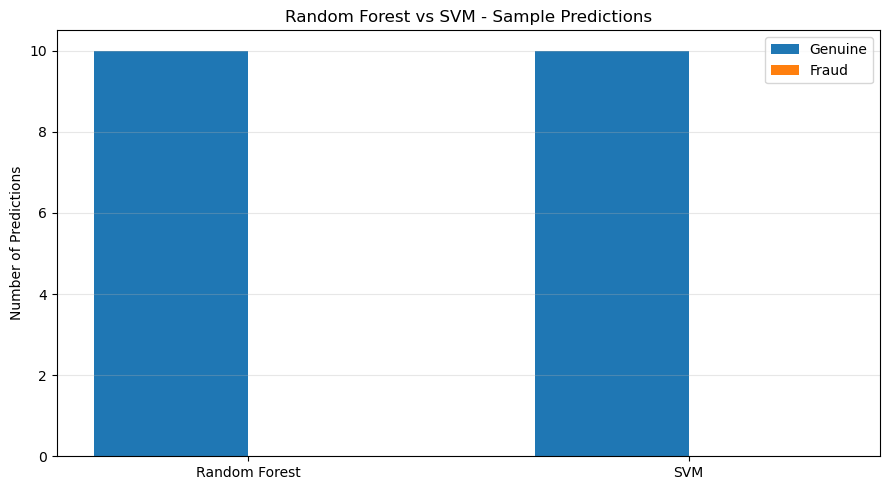


BOTH MODELS PASSED THE SAMPLE INFERENCE TEST


In [5]:

import numpy as np
import matplotlib.pyplot as plt

print("=" * 55)
print("RANDOM FOREST AND SVM - ARTIFACT VERIFICATION")
print("=" * 55)

# --------------------------------------------------
# 1. Verify Random Forest
# --------------------------------------------------

assert rf_model_loaded is not None, "Random Forest model is missing"
assert preprocessor_loaded is not None, "RF preprocessor is missing"
assert len(feature_columns_loaded) == 37, "Unexpected RF feature count"

# Use the already loaded, preprocessed test data
rf_sample = X_test_processed[:10]

rf_probabilities = rf_model_loaded.predict_proba(rf_sample)[:, 1]
rf_predictions = (
    rf_probabilities >= rf_threshold_loaded
).astype(int)

print("\nRandom Forest:")
print("Model:", type(rf_model_loaded).__name__)
print("Features:", len(feature_columns_loaded))
print("Threshold:", rf_threshold_loaded)
print("Sample predictions:", rf_predictions)


# --------------------------------------------------
# 2. Verify SVM
# --------------------------------------------------

assert svm_model is not None, "SVM model is missing"
assert X_val_processed is not None, "SVM validation data is missing"

# Use a small sample from the saved processed validation data
svm_sample = X_val_processed[:10]

svm_scores = svm_model.decision_function(svm_sample)

svm_predictions = (
    svm_scores >= best_svm_threshold
).astype(int)

print("\nSVM:")
print("Model:", type(svm_model).__name__)
print("Threshold:", best_svm_threshold)
print("Sample predictions:", svm_predictions)


# --------------------------------------------------
# 3. Plot prediction comparison
# --------------------------------------------------

models = ["Random Forest", "SVM"]

rf_counts = [
    np.sum(rf_predictions == 0),
    np.sum(rf_predictions == 1)
]

svm_counts = [
    np.sum(svm_predictions == 0),
    np.sum(svm_predictions == 1)
]

x = np.arange(len(models))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(
    x - width / 2,
    [rf_counts[0], svm_counts[0]],
    width,
    label="Genuine"
)

ax.bar(
    x + width / 2,
    [rf_counts[1], svm_counts[1]],
    width,
    label="Fraud"
)

ax.set_title("Random Forest vs SVM - Sample Predictions")
ax.set_ylabel("Number of Predictions")
ax.set_xticks(x)
ax.set_xticklabels(models)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\n" + "=" * 55)
print("BOTH MODELS PASSED THE SAMPLE INFERENCE TEST")
print("=" * 55)
